In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

df = pd.read_csv('evaluated_results.csv')

# coerce LLM score columns to numeric (turns 'skipped (generation error)' → NaN)
for col in ['llm_accuracy', 'llm_coherence', 'llm_language']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# flag error rows
df['is_error'] = df['generated_abstract'].astype(str).str.startswith('ERROR:')

NEIGHBOR_RANGE = list(range(1, 21))
print(f'{len(df)} rows  |  {df["is_error"].sum()} generation errors')
df.head(3)

200 rows  |  37 generation errors


,node_id,mag_id,original_abstract,generated_abstract,rouge1_f,rouge2_f,rougeL_f,bertscore_p,bertscore_r,bertscore_f1,llm_accuracy,llm_coherence,llm_language,num_of_neighbors,is_error
0,769,2942669846,Reinforcement learning usually makes use of nu...,This paper presents a novel approach to deep r...,0.2936,0.0556,0.1743,0.8668,0.8483,0.8575,3.0,7.0,8.0,4,False
1,2012,2913127348,Gatherings of thousands to millions of people ...,This paper presents a novel deep convolutional...,0.2833,0.0087,0.1545,0.8479,0.8306,0.8391,1.0,8.0,8.0,8,False
2,3364,2942522480,"Recently, a method called the Mutual Informati...",This paper presents a novel application of Inf...,0.3463,0.0641,0.1979,0.8369,0.8346,0.8358,1.0,8.0,8.0,4,False


In [3]:
# ── shared plot style ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.35,
    'grid.linestyle': '--',
})

def bar_plot(series: pd.Series, title: str, ylabel: str,
             color: str, ylim=None, int_yaxis=False):
    """Bar chart with one bar per neighbour count (1-20)."""
    values = [series.get(n, np.nan) for n in NEIGHBOR_RANGE]

    fig, ax = plt.subplots(figsize=(11, 4))
    bars = ax.bar(NEIGHBOR_RANGE, values, color=color, edgecolor='white', linewidth=0.6)

    # label bars that have data
    for bar, v in zip(bars, values):
        if not np.isnan(v):
            label = f'{int(v)}' if int_yaxis else f'{v:.3f}'
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004 * (bar.get_height() or 1),
                    label, ha='center', va='bottom', fontsize=7)

    ax.set_xticks(NEIGHBOR_RANGE)
    ax.set_xlabel('Number of neighbours', fontsize=11)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    if ylim:
        ax.set_ylim(*ylim)
    if int_yaxis:
        ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    fig.tight_layout()
    plt.show()

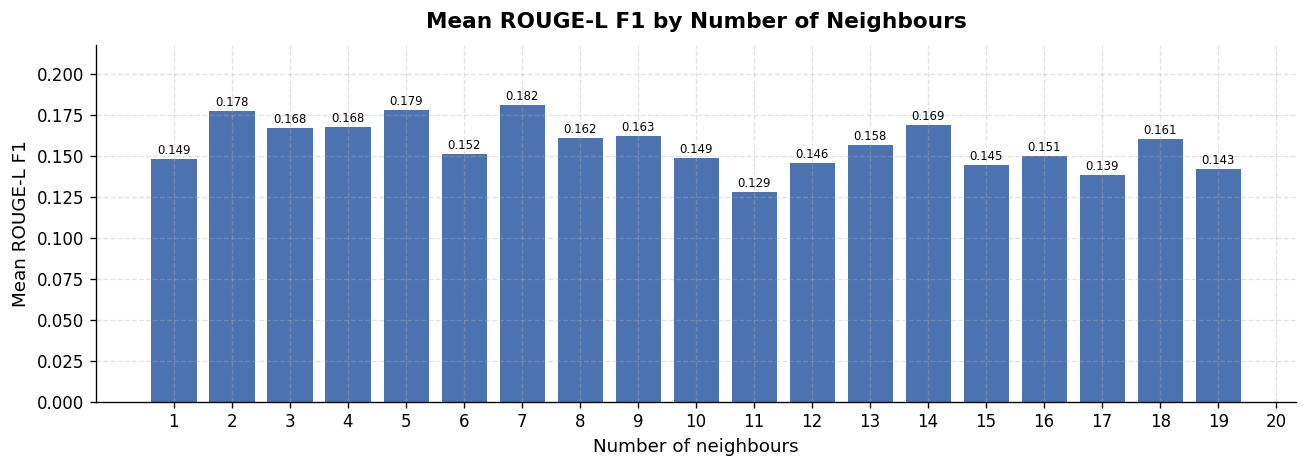

In [4]:
# ── 1. Mean ROUGE-L F1 ────────────────────────────────────────────────────────
rougel_mean = df.groupby('num_of_neighbors')['rougeL_f'].mean()
bar_plot(rougel_mean,
         title='Mean ROUGE-L F1 by Number of Neighbours',
         ylabel='Mean ROUGE-L F1',
         color='#4C72B0',
         ylim=(0, max(rougel_mean.dropna()) * 1.2))

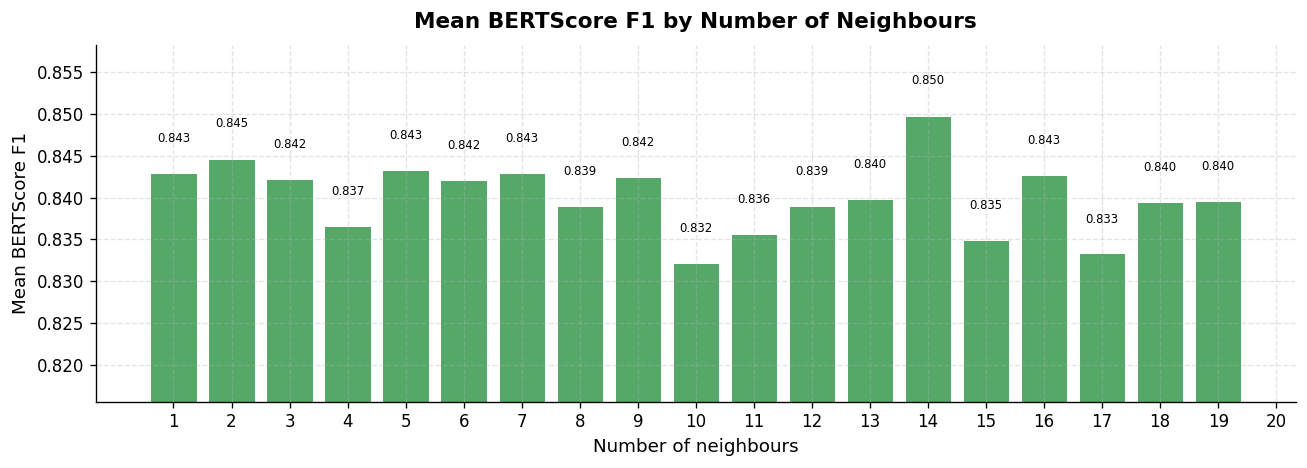

In [5]:
# ── 2. Mean BERTScore F1 ──────────────────────────────────────────────────────
bert_mean = df.groupby('num_of_neighbors')['bertscore_f1'].mean()
ymin = bert_mean.dropna().min() * 0.98
ymax = bert_mean.dropna().max() * 1.01
bar_plot(bert_mean,
         title='Mean BERTScore F1 by Number of Neighbours',
         ylabel='Mean BERTScore F1',
         color='#55A868',
         ylim=(ymin, ymax))

Overall mean LLM accuracy: 2.479
Successfully generated (non-error): 163 / 200


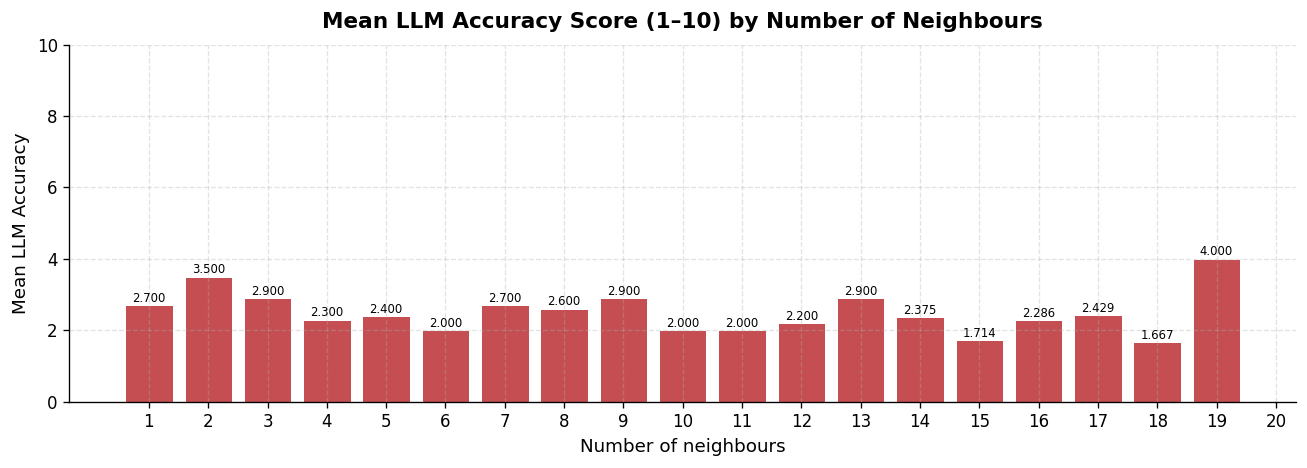

In [12]:
# ── 3. Mean LLM Accuracy ──────────────────────────────────────────────────────
acc_mean = df.groupby('num_of_neighbors')['llm_accuracy'].mean()
overall_acc_mean = df['llm_accuracy'].mean()
num_successful = (~df['is_error']).sum()
print(f'Overall mean LLM accuracy: {overall_acc_mean:.3f}')
print(f'Successfully generated (non-error): {num_successful} / {len(df)}')
bar_plot(acc_mean,
         title='Mean LLM Accuracy Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Accuracy',
         color='#C44E52',
         ylim=(0, 10))

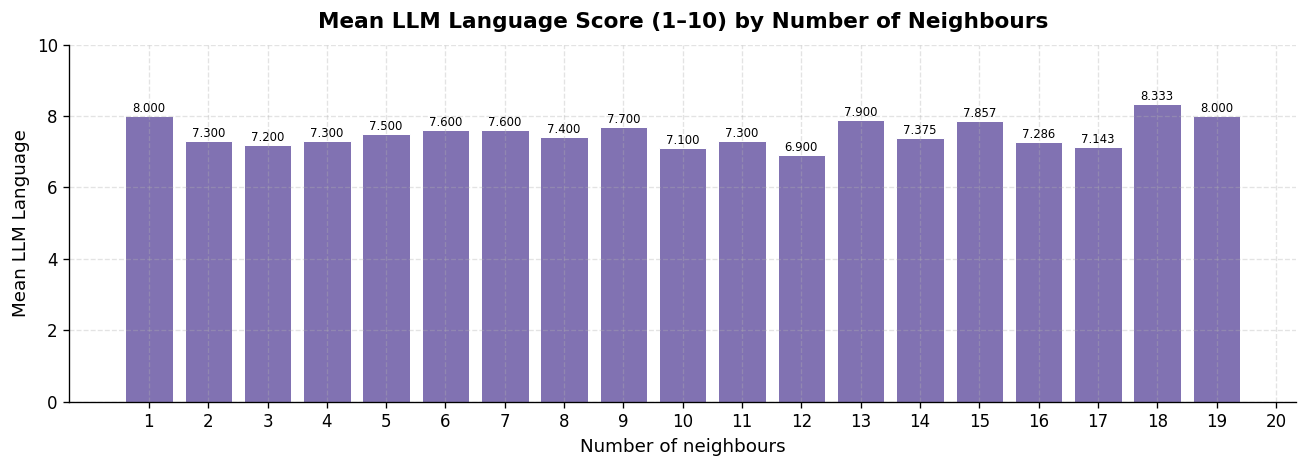

In [7]:
# ── 4. Mean LLM Language ──────────────────────────────────────────────────────
lang_mean = df.groupby('num_of_neighbors')['llm_language'].mean()
bar_plot(lang_mean,
         title='Mean LLM Language Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Language',
         color='#8172B2',
         ylim=(0, 10))

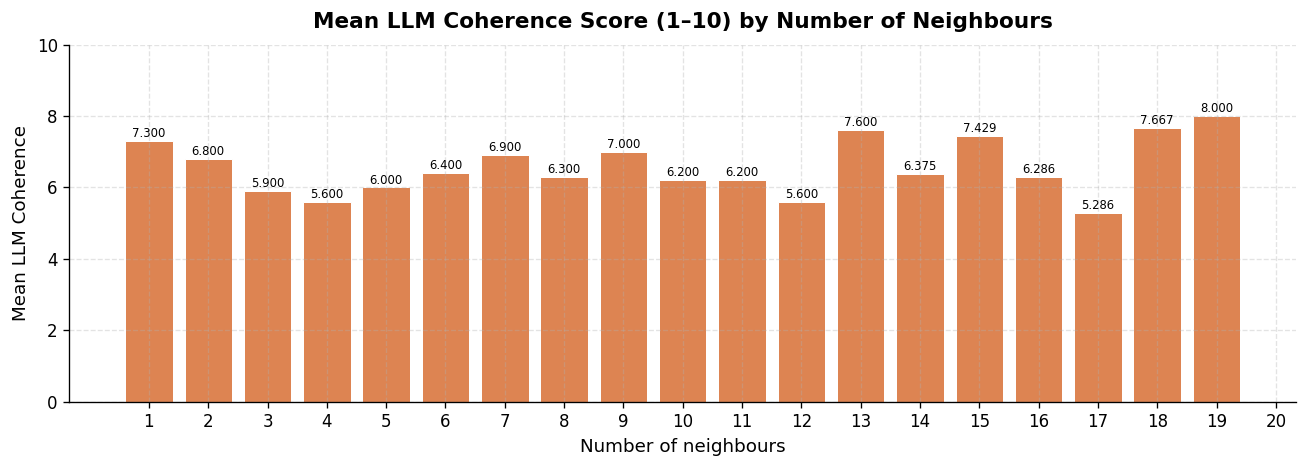

In [8]:
# ── 5. Mean LLM Coherence ─────────────────────────────────────────────────────
coh_mean = df.groupby('num_of_neighbors')['llm_coherence'].mean()
bar_plot(coh_mean,
         title='Mean LLM Coherence Score (1–10) by Number of Neighbours',
         ylabel='Mean LLM Coherence',
         color='#DD8452',
         ylim=(0, 10))

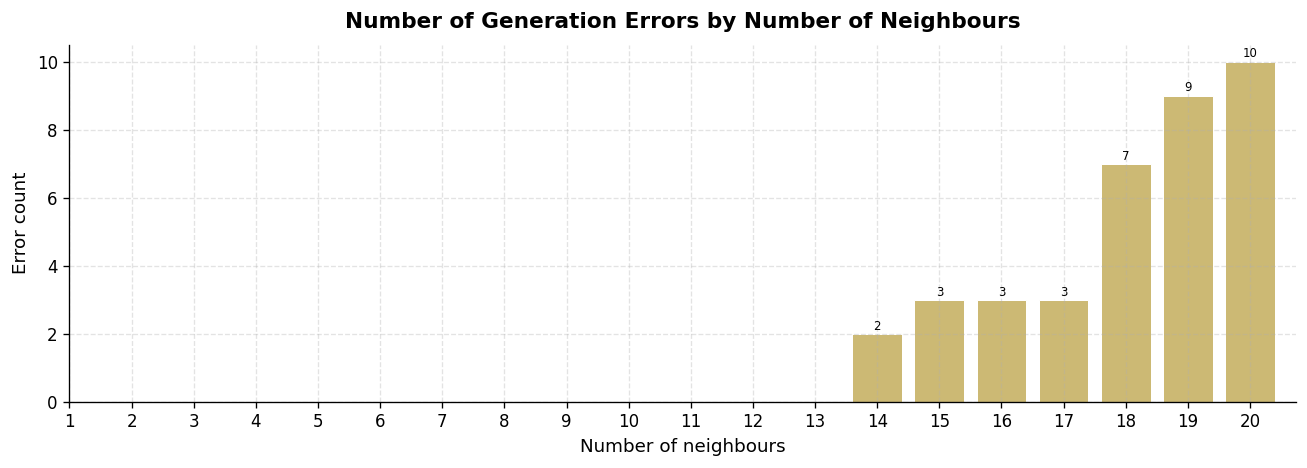

In [9]:
# ── 6. Number of Errors ───────────────────────────────────────────────────────
error_counts = df[df['is_error']].groupby('num_of_neighbors').size()
bar_plot(error_counts,
         title='Number of Generation Errors by Number of Neighbours',
         ylabel='Error count',
         color='#CCB974',
         int_yaxis=True)

In [10]:
# ── 2 examples per llm_accuracy score ────────────────────────────────────────
sample = (
    df[df['llm_accuracy'].notna()]
    .sort_values('llm_accuracy')
    .groupby('llm_accuracy', sort=True)
    .apply(lambda g: g.head(2))
    .reset_index(drop=True)
    [['node_id', 'original_abstract', 'generated_abstract', 'llm_accuracy']]
)

pd.set_option('display.max_colwidth', 2000)
sample

/var/folders/zc/tkfty0q10mx3n2n85rgs661h0000gn/T/ipykernel_31189/263653425.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: g.head(2))


,node_id,original_abstract,generated_abstract,llm_accuracy
0,63147,"With the growing importance of personalized recommendation, numerous recommendation models have been proposed recently. Among them, Matrix Factorization (MF) based models are the most widely used in the recommendation field due to their high performance. However, MF based models suffer from cold start problems where user-item interactions are sparse. To deal with this problem, content based recommendation models which use the auxiliary attributes of users and items have been proposed. Since these models use auxiliary attributes, they are effective in cold start settings. However, most of the proposed models are either unable to capture complex feature interactions or not properly designed to combine user-item feedback information with content information. In this paper, we propose Self-Attentive Integration Network (SAIN) which is a model that effectively combines user-item feedback information and auxiliary information for recommendation task. In SAIN, a self-attention mechanism is used in the feature-level interaction layer to effectively consider interactions between multiple features, while the information integration layer adaptively combines content and feedback information. The experimental results on two public datasets show that our model outperforms the state-of-the-art models by 2.13%","This paper presents a new application of the Transformer model, a simple network architecture based solely on attention mechanisms, for various natural language processing tasks. The Transformer outperforms the dominant sequence transduction models, which rely on complex recurrent or convolutional neural networks, in machine translation tasks while requiring less time to train. Additionally, the authors propose a novel model, Neural Factorization Machine (NFM), which combines the linearity of factorization machines with the non-linearity of neural networks to effectively model second-order and higher-order feature interactions in sparse predictive analytics. Finally, the paper introduces the eXtreme Deep Factorization Machine (xDeepFM), a combination of a Compressed Interaction Network and a classical deep neural network, which learns both explicit and implicit feature interactions for recommender systems. These innovative approaches demonstrate the potential of attention-based models and non-linear feature interactions for various NLP tasks.",1.0
1,39653,"Understanding the vulnerability of linguistic features extracted from noisy text is important for both developing better health text classification models and for interpreting vulnerabilities of natural language models. In this paper, we investigate how generic language characteristics, such as syntax or the lexicon, are impacted by artificial text alterations. The vulnerability of features is analysed from two perspectives: (1) the level of feature value change, and (2) the level of change of feature predictive power as a result of text modifications. We show that lexical features are more sensitive to text modifications than syntactic ones. However, we also demonstrate that these smaller changes of syntactic features have a stronger influence on classification performance downstream, compared to the impact of changes to lexical features. Results are validated across three datasets representing different text-classification tasks, with different levels of lexical and syntactic complexity of both conversational and written language.","This paper presents a new application of combining normative data with speech-based assessments for detecting Alzheimer's disease (AD). The authors augmented the DementiaBank dataset with two normative data sets, the Wisconsin Longitudinal Study and Talk2Me, to create a more generalized model. By using minority class oversampling with ADASYN, the combined dataset outperformed state-of-the-art results in binary classification of people with and without AD in DementiaBank. The study hig

In [11]:
# ── Negative category counts ──────────────────────────────────────────────────
NEG_COLS = [
    'cat_wrong_domain', 'cat_multi_paper_contamination', 'cat_wrong_methodology',
    'cat_wrong_task', 'cat_too_generic', 'cat_truncated_incomplete',
]
NEG_LABELS = [
    'Wrong domain', 'Multi-paper contamination', 'Wrong methodology',
    'Wrong task', 'Too generic', 'Truncated / incomplete',
]

neg_counts = df[NEG_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(NEG_LABELS, neg_counts, color='#C44E52', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, neg_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Negative category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()

KeyError: "None of [Index(['cat_wrong_domain', 'cat_multi_paper_contamination',\n       'cat_wrong_methodology', 'cat_wrong_task', 'cat_too_generic',\n       'cat_truncated_incomplete'],\n      dtype='object')] are in the [columns]"

Category definitions:
- wrong_domain: The generated abstract is about a completely different research field or application domain from the original.
- multi_paper_contamination: The text reads like a stitched-together mixture of multiple unrelated papers rather than one coherent abstract.
- wrong_methodology: The domain is broadly correct but describes different techniques or algorithms than the original.
- wrong_task: Same broad field but the specific problem being solved is different (e.g., classification instead of regression, MT instead of summarisation).
- too_generic: Correct domain but described at such a high level of generality that it lacks the specific terminology and framing of the original.
- truncated_incomplete: The abstract ends abruptly mid-sentence or is clearly unfinished.


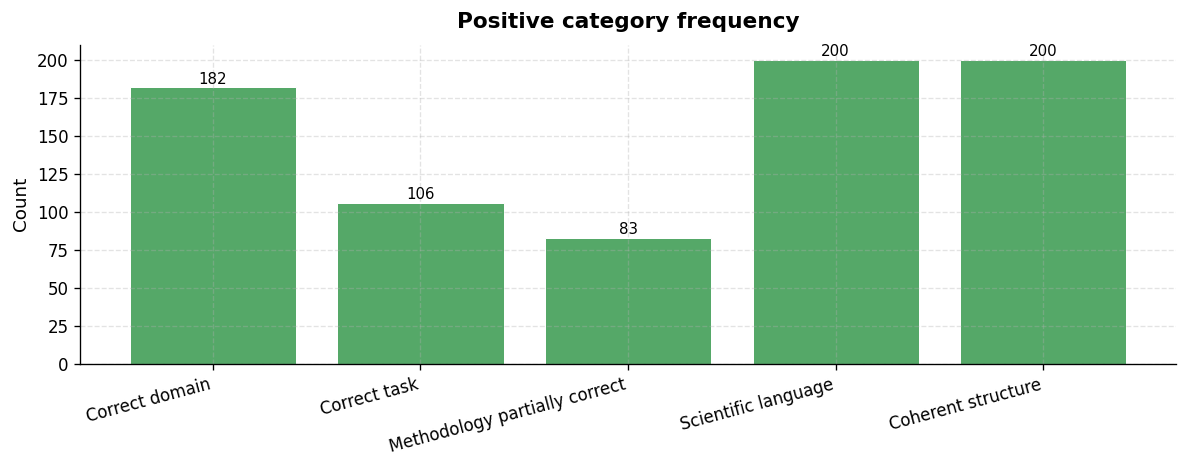

In [ ]:
# ── Positive category counts ──────────────────────────────────────────────────
POS_COLS = [
    'cat_correct_domain', 'cat_correct_task', 'cat_methodology_partially_correct',
    'cat_scientific_language', 'cat_coherent_structure',
]
POS_LABELS = [
    'Correct domain', 'Correct task', 'Methodology partially correct',
    'Scientific language', 'Coherent structure',
]

pos_counts = df[POS_COLS].sum().values

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(POS_LABELS, pos_counts, color='#55A868', edgecolor='white', linewidth=0.6)
for bar, v in zip(bars, pos_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            str(int(v)), ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Count', fontsize=11)
ax.set_title('Positive category frequency', fontsize=13, fontweight='bold', pad=10)
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
plt.xticks(rotation=15, ha='right')
fig.tight_layout()
plt.show()